# Effect of non-sphericity on the optical properties of marine particles

Companion of `sensitivity_marine_particles.ipynb`: same refractive indices relative to seawater, size
distributions and wavelengths, for non-absorbing and `pigment`-absorbing particles (the imaginary part
has little effect on the scattering matrix), for randomly oriented spheroids compared with spheres:

* oblate and prolate spheroids with aspect ratios 1.2, 2 and 3,
* a mixture of oblate and prolate spheroids with a log-normal aspect-ratio distribution,
* spheres (Mie).

**Assumptions**

* Refractive index relative to seawater ($n_w$ = 1.34), computations at the wavelength in water.
* Particle sizes are **cross-section-equivalent radii** $r_c = \sqrt{C_{geo}/\pi}$, with $C_{geo}$ the
  orientation-averaged geometric cross section (MOPSMAP `size_equ cs`), between 0.05 and 40 µm. The
  efficiency factors $Q = C / \langle C_{geo} \rangle$ thus compare particles with the same projected area.
* Random orientation (MOPSMAP).

**Methods and limitations**

* MOPSMAP spheroid dataset: T-matrix method up to a size parameter $x \approx 32$ and improved
  geometric optics (IGOM) above $x \approx 34$, up to $x$ = 1040 for $m_r \ge$ 1.04. Spheres use Mie theory
  over the whole range.
* $m_r$ = 1.02 cannot be computed: the spheroid dataset only reaches $x \le 63$ at the neighbouring node
  $m_r$ = 1.00, and no T-matrix code is used here. The analysis covers the dataset nodes 1.04 to 1.20.
* Geometric optics assumes a large phase shift $2x(m_r - 1)$: close to $m_r = 1$ the IGOM part is
  approximate, and the transition from T-matrix to IGOM is discontinuous at $m_r$ = 1.04 (section 3).
  Spheroids with an aspect ratio of 1.2 are therefore used as a **near-spherical reference computed
  with the same methods**, to separate the effect of the shape from the change of method
  (Mie vs T-matrix/IGOM).
* As shown in the companion notebook, MOPSMAP underestimates the absorption of large weakly absorbing
  particles ($0 < m_i < 5.4 \times 10^{-4}$) by up to 14 %; the same applies here.

**Requirements**: MOPSMAP installation (`MOPSMAP_DIR`) and `pip install -e .` from the repository root.
The 640 MOPSMAP runs take about 1 minute on 40 CPUs.

## 1. Setup

In [1]:
import os
os.environ.setdefault('MOPSMAP_DIR', '/data/vrtc/aerosol/mopsmap')

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import dask

from mopsmap_tbx.opac_mopsmap import MOPSMAP_DATA, ROOT, compute_tasks, run_mopsmap

odir = ROOT / 'scatmat' / 'sensitivity'
idir = odir / 'inputs'
idir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'lines.linewidth': 1.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 100, 'savefig.dpi': 200,
})
PSD_COLORS = ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b']
print('MOPSMAP:', os.environ['MOPSMAP_DIR'], '| dask', dask.__version__)

MOPSMAP: /data/vrtc/aerosol/mopsmap | dask 2024.8.0


In [2]:
n_w = 1.34                                   # refractive index of seawater
wl = np.array([400, 412.5, 442.5, 490, 510, 560, 620, 665, 673.75, 681.25,
               708.75, 753.75, 778.75, 865, 885, 900])  # OLCI bands (nm, vacuum)
wl_w = wl * 1e-3 / n_w                       # wavelength in water (µm)
mr_list = [1.04, 1.08, 1.12, 1.16, 1.20]     # MOPSMAP dataset nodes

r_min, r_max = 0.05, 40.                     # cross-section-equivalent radius range (µm)
r = np.logspace(np.log10(r_min), np.log10(r_max), 1200)
theta = np.loadtxt(Path(MOPSMAP_DATA) / 'scat_angle_grid.txt')
print(f'max size parameter: {2 * np.pi * r_max / wl_w.min():.0f} (spheroid dataset: 1040)')

max size parameter: 842 (spheroid dataset: 1040)


### Particle shapes

MOPSMAP aspect ratio $\epsilon \ge 1$: ratio of the longest to the shortest axis. The mixture is made of
50 % oblate and 50 % prolate spheroids with the modified log-normal aspect-ratio distribution of MOPSMAP,
$f(\epsilon) \propto \frac{1}{\epsilon - 1} \exp\left[-\frac{1}{2}\left(\frac{\ln(\epsilon - 1) - \ln(\epsilon_0 - 1)}{\sigma_{ar}}\right)^2\right]$
with $\epsilon_0$ = 1.6 and $\sigma_{ar}$ = 0.6, for $1.2 \le \epsilon \le 5$.

In [3]:
particles = {
    'oblate 3': 'spheroid oblate 3.0',
    'oblate 2': 'spheroid oblate 2.0',
    'oblate 1.2': 'spheroid oblate 1.2',
    'sphere': 'sphere',
    'prolate 1.2': 'spheroid prolate 1.2',
    'prolate 2': 'spheroid prolate 2.0',
    'prolate 3': 'spheroid prolate 3.0',
    'mixture': 'spheroid log_normal 1.0 0.5 1.6 0.6',
}
particle_ids = list(particles)
spheroid_ids = [p for p in particle_ids if p not in ('sphere', 'mixture')]

# diverging: oblate (blue) / sphere (neutral) / prolate (red), darker for larger aspect ratios
STYLE = {
    'oblate 3': dict(color='#104281'), 'oblate 2': dict(color='#2a78d6'), 'oblate 1.2': dict(color='#86b6ef'),
    'sphere': dict(color='#5f5e5a', lw=2.4),
    'prolate 1.2': dict(color='#ef9c95'), 'prolate 2': dict(color='#e34948'), 'prolate 3': dict(color='#9e2324'),
    'mixture': dict(color='#0b0b0b', ls='--'),
}

### Size distributions and imaginary part

Same definitions as in the companion notebook: power law $n(r) \propto r^{-\xi}$ with $\xi$ = 3 to 4.5,
log-normal with $r_{mod}$ = 0.5 to 5 µm and $\sigma$ = 1.8, and the `none` and `pigment` spectral shapes of
$m_i$.

In [4]:
def junge(r, xi):
    return r ** -xi


def lognormal(r, r_mod, sigma):
    return np.exp(-0.5 * (np.log(r / r_mod) / np.log(sigma)) ** 2) / r


def gauss(lam, lam0, s):
    return np.exp(-0.5 * ((lam - lam0) / s) ** 2)


psd_def = {
    'J3.0': ('Junge', 'ξ = 3.0', junge(r, 3.0)),
    'J3.5': ('Junge', 'ξ = 3.5', junge(r, 3.5)),
    'J4.0': ('Junge', 'ξ = 4.0', junge(r, 4.0)),
    'J4.5': ('Junge', 'ξ = 4.5', junge(r, 4.5)),
    'LN0.5': ('log-normal', 'r_mod = 0.5 µm', lognormal(r, 0.5, 1.8)),
    'LN1': ('log-normal', 'r_mod = 1 µm', lognormal(r, 1., 1.8)),
    'LN2': ('log-normal', 'r_mod = 2 µm', lognormal(r, 2., 1.8)),
    'LN5': ('log-normal', 'r_mod = 5 µm', lognormal(r, 5., 1.8)),
}
psd_ids = list(psd_def)
dr = np.gradient(r)
n_r = np.array([v[2] / np.sum(v[2] * dr) for v in psd_def.values()])  # dN/dr, N = 1

mi_def = {
    'none': np.zeros_like(wl),
    'pigment': 2e-4 + 3e-3 * gauss(wl, 442.5, 35) + 1.5e-3 * gauss(wl, 675, 15),
}
absorptions = list(mi_def)

## 2. MOPSMAP spheroid dataset at low $m_r$

Single-particle extinction efficiency of the dataset (non-absorbing) for spheres and spheroids with an
aspect ratio of 2. The dataset parameter $\epsilon$ is the aspect ratio for oblate spheroids and its inverse
for prolate spheroids (Mishchenko convention). The gray band marks the gap between the largest T-matrix
($x$ = 31.7) and the smallest IGOM ($x$ = 33.6) size parameters.

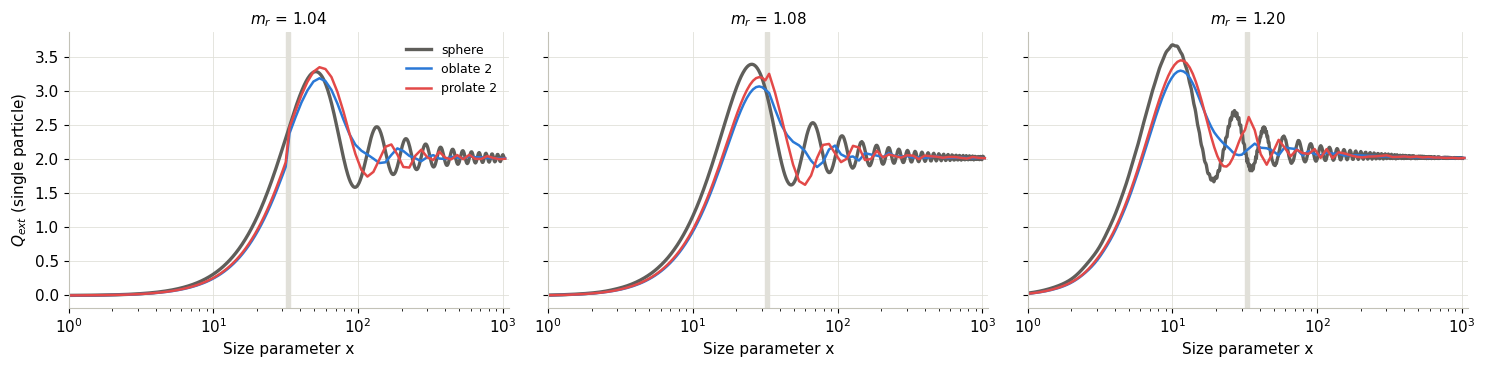

In [5]:
dset = Path(MOPSMAP_DATA) / 'optical_dataset'
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, mr in zip(axs, [1.04, 1.08, 1.20]):
    s = xr.open_dataset(dset / 'spheres' / f'sphere_{mr:.4f}_0.000000.nc')
    ax.plot(s.sizepara, s.qext, label='sphere', **STYLE['sphere'])
    for name, eps in [('oblate 2', 2.0), ('prolate 2', 0.5)]:
        d = xr.open_dataset(dset / 'spheroids_merged' / f'spheroid_merged_{eps:.3f}_{mr:.4f}_0.000000.nc')
        ax.plot(d.sizepara, d.qext, label=name, **STYLE[name])
    ax.axvspan(31.667, 33.638, color='#e1e0d9', zorder=-1)
    ax.set_xscale('log')
    ax.set_xlim(1, 1100)
    ax.set_title(f'$m_r$ = {mr:.2f}')
    ax.set_xlabel('Size parameter x')
axs[0].set_ylabel('$Q_{ext}$ (single particle)')
axs[0].legend(frameon=False)
plt.tight_layout()

At $m_r$ = 1.04 the extinction efficiency of the spheroids jumps by about 25 % between the T-matrix and the
IGOM ranges, to values close to those of spheres: in this regime, differences between spheres and
spheroids for size distributions dominated by particles with $x > 34$ partly reflect the change of method.
The transition is smoother for $m_r \ge$ 1.08.

## 3. Computations

One MOPSMAP run per (particle shape, $m_r$, $m_i$ shape, size distribution) for all wavelengths, computed in
parallel with Dask's threaded scheduler.

In [6]:
MOPSMAP_INPUT = '''mode 1 size distr_file dndr '{psd}'
mode 1 refrac file '{refr}'
mode 1 shape {shape}
size_equ cs
wavelength from_refrac_file
scatlib '{data}/optical_dataset'
output integrated
output scattering_matrix
output theta_file '{data}/scat_angle_grid.txt'
output digits 10
'''

for k, p in enumerate(psd_ids):
    np.savetxt(idir / f'psd_{p}.txt', np.c_[r, n_r[k]], fmt='%.8e')
for mr in mr_list:
    for a in absorptions:
        np.savetxt(idir / f'refr_{mr:.2f}_{a}.txt', np.c_[wl_w, np.full_like(wl_w, mr), mi_def[a]], fmt='%.8e')


@dask.delayed
def mopsmap_case(shape, psd_file, refr_file):
    # MOPSMAP returns Qext, ssa, g (wl,) and the scattering matrix (wl, theta, element)
    out = run_mopsmap(MOPSMAP_INPUT.format(shape=shape, psd=psd_file, refr=refr_file, data=MOPSMAP_DATA))
    integ = np.array([l.split()[1:] for l in out.splitlines() if l.startswith('integrated')], float)
    if len(integ) != len(wl_w):
        raise RuntimeError(f'MOPSMAP failed for {shape}, {psd_file}, {refr_file}:\n{out[-2000:]}')
    sm = np.array([l.split()[3:9] for l in out.splitlines() if l.startswith('scattering_matrix')], float)
    return (integ[:, 1] / integ[:, 6], integ[:, 2], integ[:, 3],
            sm.reshape(len(wl_w), len(theta), 6).astype('float32'))


keys = [(pa, mr, a, p) for pa in particle_ids for mr in mr_list for a in absorptions for p in psd_ids]
tasks = [mopsmap_case(particles[pa], idir / f'psd_{p}.txt', idir / f'refr_{mr:.2f}_{a}.txt')
         for pa, mr, a, p in keys]
print(len(tasks), 'MOPSMAP runs')
t0 = time.perf_counter()
res = compute_tasks(tasks, progress=False)
print(f'done in {time.perf_counter() - t0:.0f} s')

640 MOPSMAP runs


done in 55 s


In [7]:
elements = ['a1', 'a2', 'a3', 'a4', 'b1', 'b2']
shp = (len(particle_ids), len(mr_list), len(absorptions), len(psd_ids))
Qext, ssa, g, F = (np.array([x[i] for x in res]).reshape(shp + np.shape(res[0][i])) for i in range(4))
d5 = ('particle', 'mr', 'absorption', 'psd', 'wl')
ds = xr.Dataset({'Qext': (d5, Qext), 'ssa': (d5, ssa), 'g': (d5, g),
                 'F': (d5 + ('theta', 'element'), F)},
                coords=dict(particle=particle_ids, mr=mr_list, absorption=absorptions, psd=psd_ids,
                            wl=wl, theta=theta, element=elements))

# derived quantities
ds = ds.assign_coords(theta_rad=('theta', np.radians(theta)))
a1 = ds.F.sel(element='a1')
a1s = a1 * np.sin(ds.theta_rad)
ds['bb_ratio'] = a1s.where(ds.theta >= 90, drop=True).integrate('theta_rad') / a1s.integrate('theta_rad')
ds['Qsca'] = ds.Qext * ds.ssa
ds['Qabs'] = ds.Qext - ds.Qsca
ds['Qbb'] = ds.Qsca * ds.bb_ratio
ds['dolp'] = -ds.F.sel(element='b1') / a1
a2_180 = ds.F.sel(element='a2', theta=180)
a1_180 = a1.sel(theta=180)
ds['depol'] = (a1_180 - a2_180) / (a1_180 + a2_180)   # linear depolarization ratio at 180°
ds

<xarray.Dataset> Size: 108MB
Dimensions:     (particle: 8, mr: 5, absorption: 2, psd: 8, wl: 16, theta: 376,
                 element: 6)
Coordinates:
  * particle    (particle) <U11 352B 'oblate 3' 'oblate 2' ... 'mixture'
  * mr          (mr) float64 40B 1.04 1.08 1.12 1.16 1.2
  * absorption  (absorption) <U7 56B 'none' 'pigment'
  * psd         (psd) <U5 160B 'J3.0' 'J3.5' 'J4.0' 'J4.5' ... 'LN1' 'LN2' 'LN5'
  * wl          (wl) float64 128B 400.0 412.5 442.5 490.0 ... 865.0 885.0 900.0
  * theta       (theta) float64 3kB 0.0 0.001 0.005 0.01 ... 179.0 179.5 180.0
  * element     (element) <U2 48B 'a1' 'a2' 'a3' 'a4' 'b1' 'b2'
    theta_rad   (theta) float64 3kB 0.0 1.745e-05 8.727e-05 ... 3.133 3.142
Data variables:
    Qext        (particle, mr, absorption, psd, wl) float64 82kB 1.258 ... 2.107
    ssa         (particle, mr, absorption, psd, wl) float64 82kB 1.0 ... 0.9706
    g           (particle, mr, absorption, psd, wl) float64 82kB 0.9775 ... 0...
    F           (particle, mr, absorption, psd, wl, theta, element) float32 92MB ...
    bb_ratio    (particle, mr, absorption, psd, wl) float64 82kB 0.004238 ......
    Qsca        (particle, mr, absorption, psd, wl) float64 82kB 1.258 ... 2.045
    Qabs        (particle, mr, absorption, psd, wl) float64 82kB 4.403e-09 .....
    Qbb         (particle, mr, absorption, psd, wl) float64 82kB 0.005331 ......
    dolp        (particle, mr, absorption, psd, wl, theta) float32 15MB -0.0 ...
    depol       (particle, mr, absorption, psd, wl) float32 41kB 0.5904 ... 0...

## 4. Effect of the particle shape

### Ratio to spheres as a function of the aspect ratio

Non-absorbing particles, $m_r$ = 1.08 and 1.16, 560 nm. Values relative to spheres (Mie) and, as dotted
lines, relative to the near-spherical spheroids ($\epsilon$ = 1.2, same methods as the other spheroids).
The last column is the linear depolarization ratio at 180°, zero for spheres.

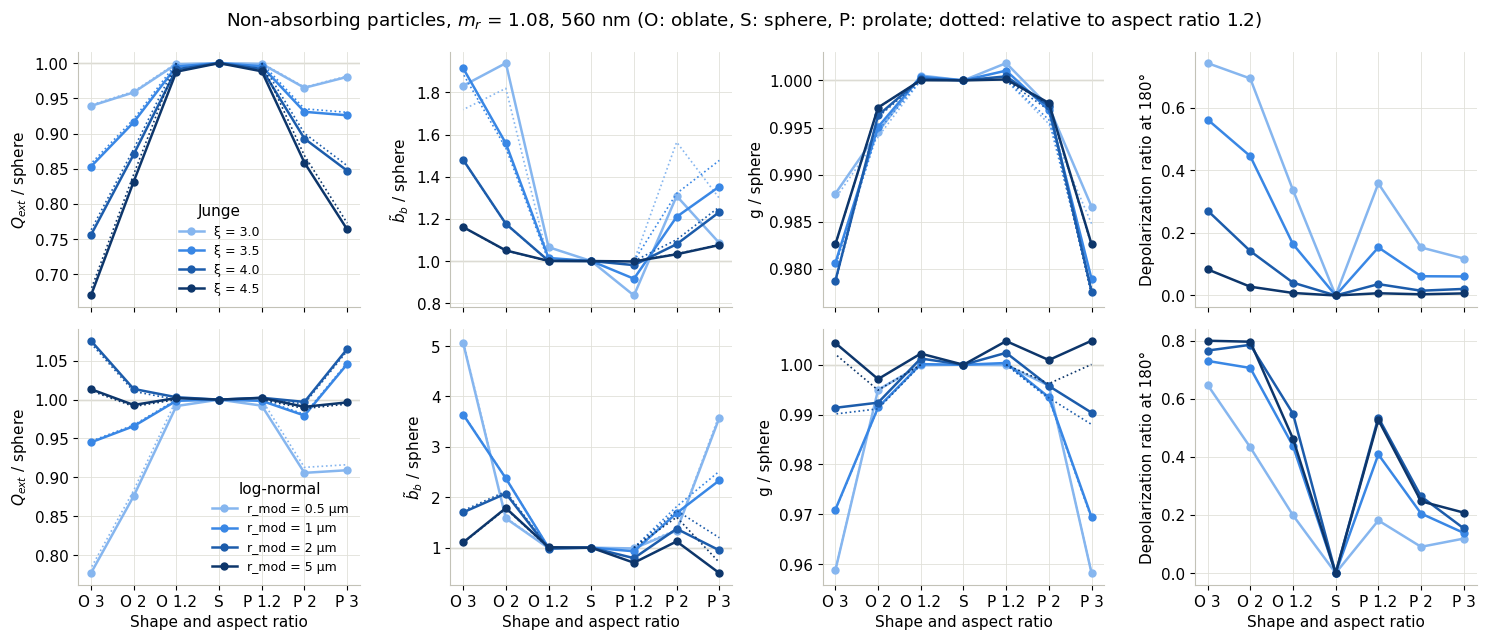

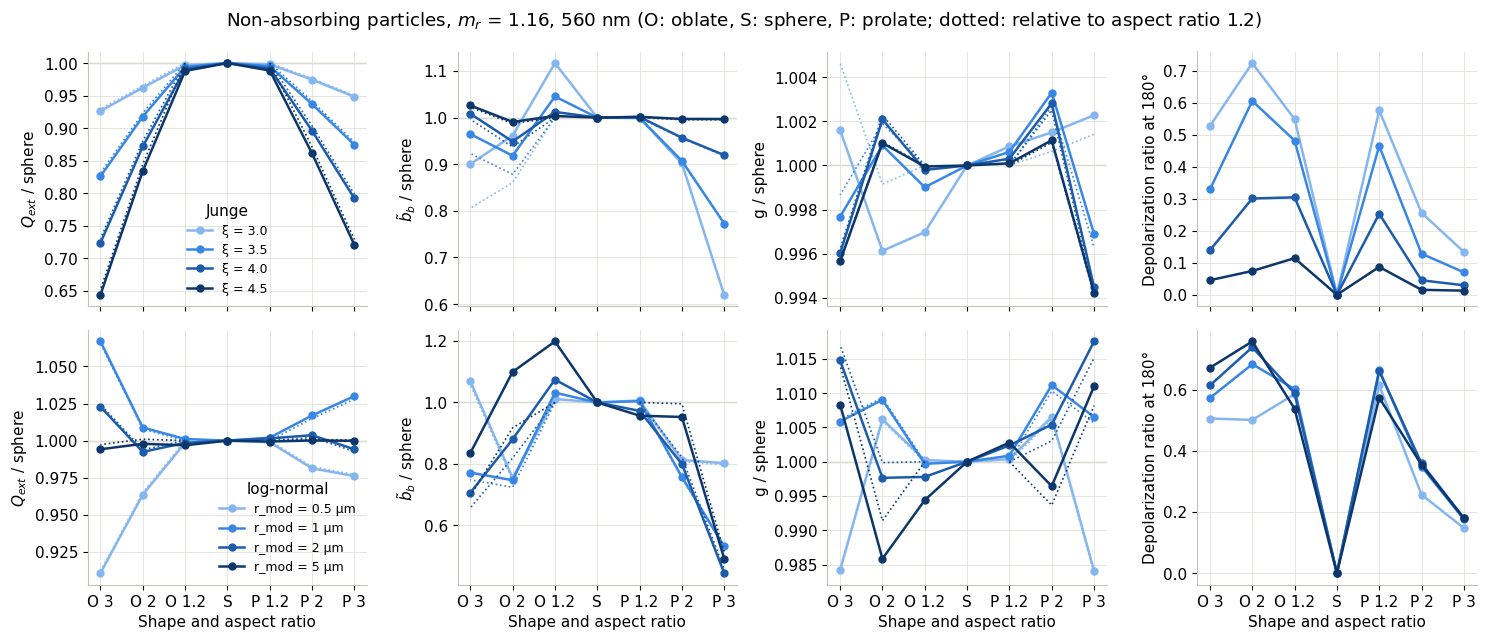

In [8]:
x_pos = {'oblate 3': -3, 'oblate 2': -2, 'oblate 1.2': -1, 'sphere': 0, 'prolate 1.2': 1, 'prolate 2': 2, 'prolate 3': 3}
xs = list(x_pos.values())
panels = [('Qext', '$Q_{ext}$ / sphere'), ('bb_ratio', '$\\tilde{b}_b$ / sphere'), ('g', 'g / sphere'),
          ('depol', 'Depolarization ratio at 180°')]
for mr in [1.08, 1.16]:
    sub = ds.sel(mr=mr, absorption='none', wl=560)
    fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
    for i, fam in enumerate(['Junge', 'log-normal']):
        ids = [p for p in psd_ids if psd_def[p][0] == fam]
        for j, (v, label) in enumerate(panels):
            ax = axs[i, j]
            for p, c in zip(ids, PSD_COLORS):
                y = sub[v].sel(psd=p)
                if v == 'depol':
                    ax.plot(xs, [float(y.sel(particle=pa)) for pa in x_pos], 'o-', ms=5, color=c, label=psd_def[p][1])
                    continue
                ref = y.sel(particle='sphere')
                ax.plot(xs, [float(y.sel(particle=pa) / ref) for pa in x_pos], 'o-', ms=5, color=c,
                        label=psd_def[p][1])
                # relative to the near-spherical spheroids, on each side
                near = {'oblate': y.sel(particle='oblate 1.2'), 'prolate': y.sel(particle='prolate 1.2')}
                for side, ids_ in [('oblate', ['oblate 1.2', 'oblate 2', 'oblate 3']),
                                   ('prolate', ['prolate 1.2', 'prolate 2', 'prolate 3'])]:
                    ax.plot([x_pos[q] for q in ids_], [float(y.sel(particle=q) / near[side]) for q in ids_],
                            ':', color=c, lw=1.2)
            if v != 'depol':
                ax.axhline(1, color='#c3c2b7', lw=1, zorder=-1)
            ax.set_ylabel(label)
        axs[i, 0].legend(title=fam, frameon=False)
    for ax in axs[1]:
        ax.set_xticks(xs)
        ax.set_xticklabels(['O 3', 'O 2', 'O 1.2', 'S', 'P 1.2', 'P 2', 'P 3'])
        ax.set_xlabel('Shape and aspect ratio')
    fig.suptitle(f'Non-absorbing particles, $m_r$ = {mr:.2f}, 560 nm (O: oblate, S: sphere, P: prolate; '
                 'dotted: relative to aspect ratio 1.2)')
    plt.tight_layout()

### Sensitivity to $m_r$ for each shape

Non-absorbing particles at 560 nm, for a steep power law ($\xi$ = 4) and the 2 µm log-normal distribution.

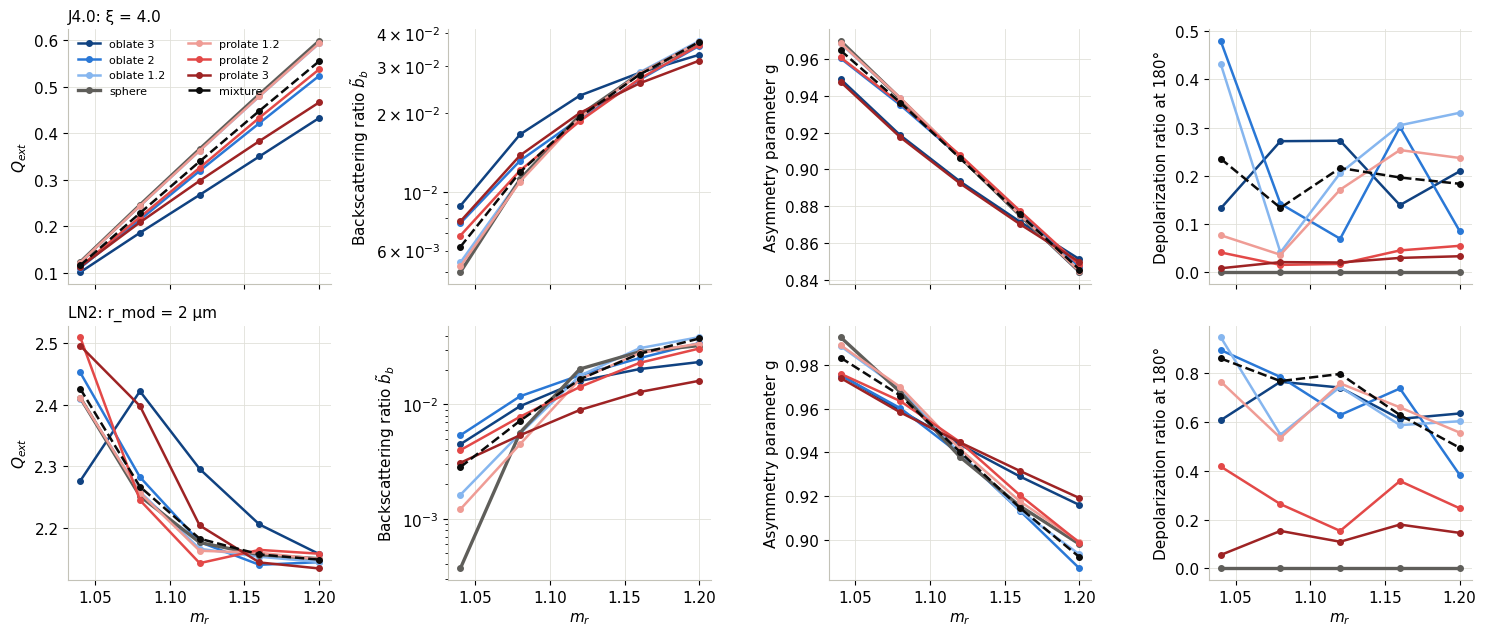

In [9]:
panels = [('Qext', '$Q_{ext}$'), ('bb_ratio', 'Backscattering ratio $\\tilde{b}_b$'), ('g', 'Asymmetry parameter g'),
          ('depol', 'Depolarization ratio at 180°')]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['J4.0', 'LN2']):
    sub = ds.sel(absorption='none', wl=560, psd=p)
    for j, (v, label) in enumerate(panels):
        ax = axs[i, j]
        for pa in particle_ids:
            ax.plot(sub.mr, sub[v].sel(particle=pa), marker='o', ms=4, label=pa, **STYLE[pa])
        ax.set_ylabel(label)
        if v == 'bb_ratio':
            ax.set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('$m_r$')
axs[0, 0].legend(frameon=False, ncol=2, fontsize=8)
plt.tight_layout()

### Scattering matrix

$m_r$ = 1.08, 560 nm, non-absorbing particles. For spheres $a_2/a_1 = 1$ and $a_4 = a_3$: departures from these
identities are the signature of non-sphericity.

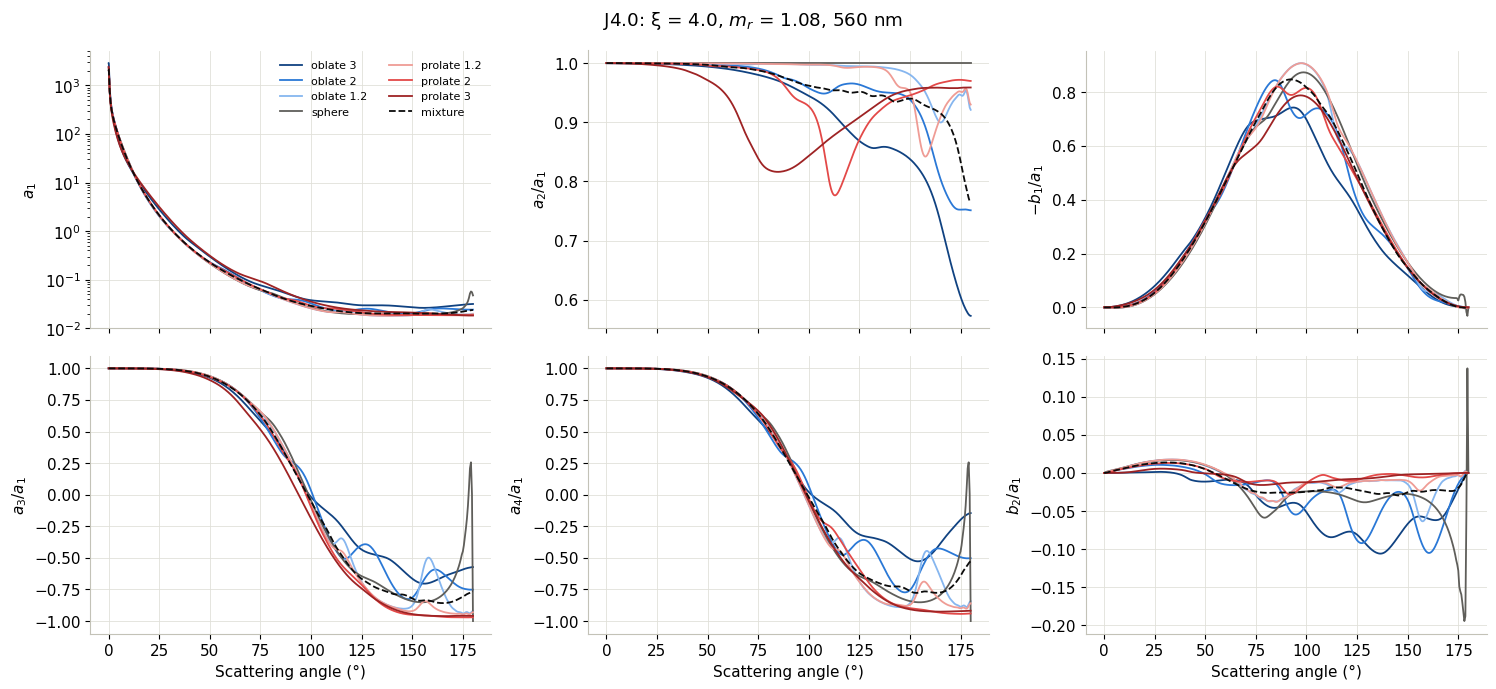

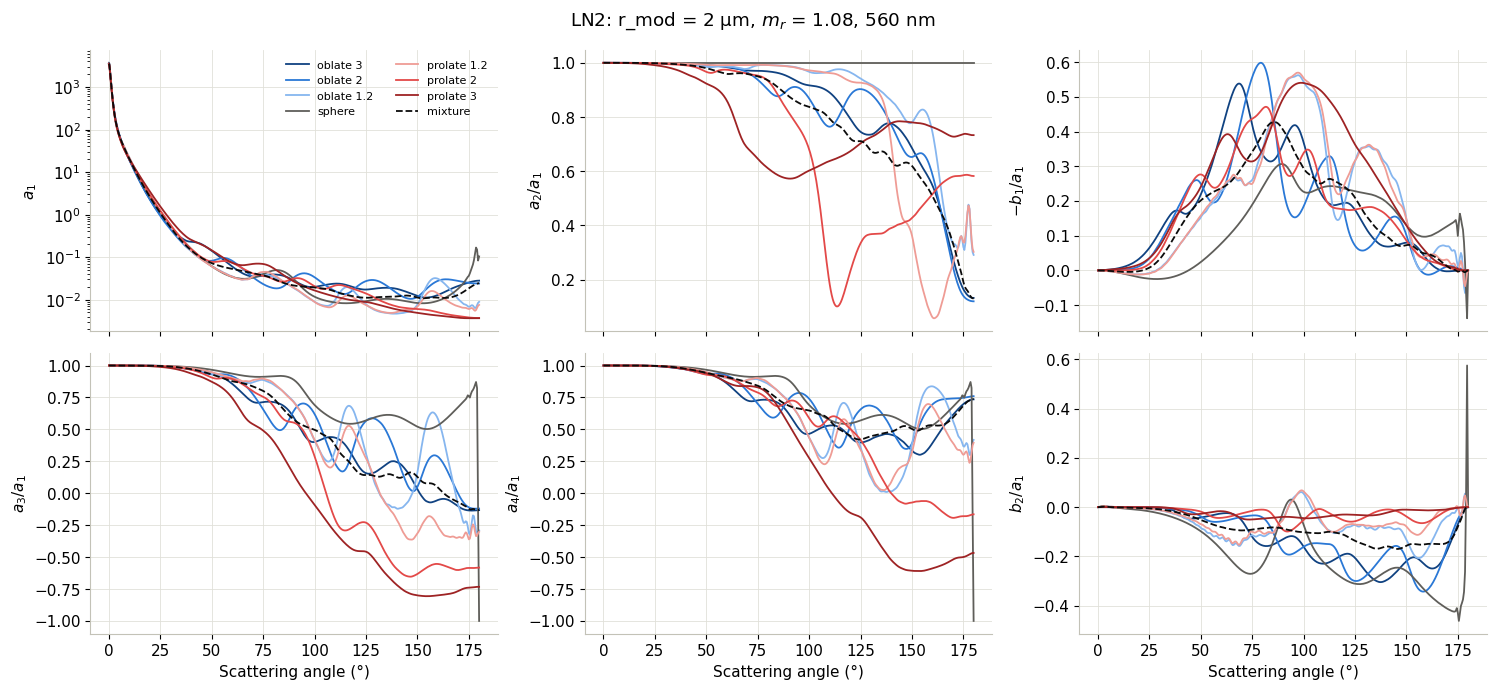

In [10]:
panels = ['a1', 'a2', 'b1', 'a3', 'a4', 'b2']
labels = {'a1': '$a_1$', 'a2': '$a_2/a_1$', 'b1': '$-b_1/a_1$', 'a3': '$a_3/a_1$', 'a4': '$a_4/a_1$', 'b2': '$b_2/a_1$'}
for p in ['J4.0', 'LN2']:
    s = ds.sel(mr=1.08, absorption='none', wl=560, psd=p)
    a1 = s.F.sel(element='a1')
    fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
    for ax, e in zip(axs.ravel(), panels):
        for pa in particle_ids:
            if e == 'a1':
                y = a1.sel(particle=pa)
            elif e == 'b1':
                y = s.dolp.sel(particle=pa)
            else:
                y = (s.F.sel(element=e) / a1).sel(particle=pa)
            ax.plot(s.theta, y, lw=1.3, label=pa, **{k: v for k, v in STYLE[pa].items() if k != 'lw'})
        ax.set_ylabel(labels[e])
    axs[0, 0].set_yscale('log')
    axs[0, 0].legend(frameon=False, ncol=2, fontsize=8)
    for ax in axs[1]:
        ax.set_xlabel('Scattering angle (°)')
    fig.suptitle(f'{p}: {psd_def[p][1]}, $m_r$ = 1.08, 560 nm')
    plt.tight_layout()

### Spectral efficiency factors

Ratio of spheroids to spheres for $Q_{ext}$, $Q_{abs}$ and $Q_{bb}$ with the `pigment` absorption, $m_r$ = 1.08.

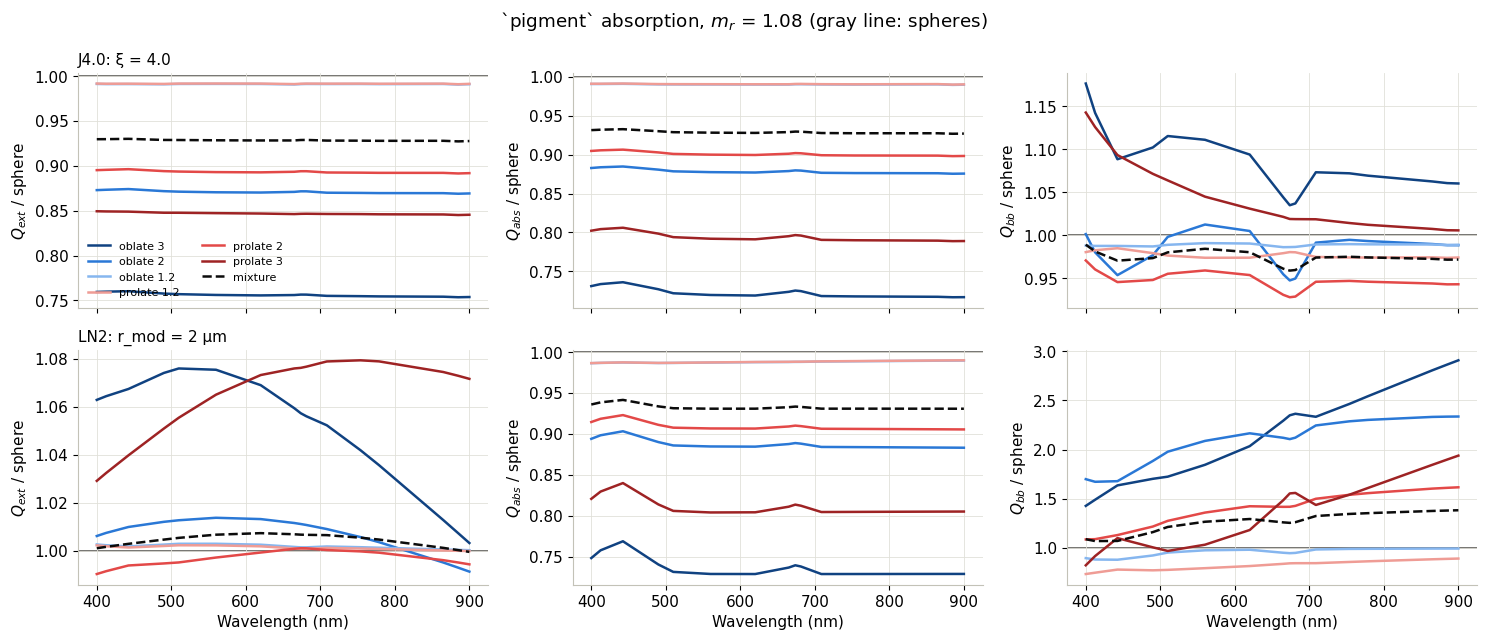

In [11]:
panels = [('Qext', '$Q_{ext}$ / sphere'), ('Qabs', '$Q_{abs}$ / sphere'), ('Qbb', '$Q_{bb}$ / sphere')]
fig, axs = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['J4.0', 'LN2']):
    sub = ds.sel(mr=1.08, absorption='pigment', psd=p)
    for j, (v, label) in enumerate(panels):
        ax = axs[i, j]
        ref = sub[v].sel(particle='sphere')
        for pa in particle_ids:
            if pa == 'sphere':
                continue
            ax.plot(wl, sub[v].sel(particle=pa) / ref, label=pa, **STYLE[pa])
        ax.axhline(1, color='#5f5e5a', lw=1.2, zorder=-1)
        ax.set_ylabel(label)
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('Wavelength (nm)')
axs[0, 0].legend(frameon=False, ncol=2, fontsize=8)
fig.suptitle('`pigment` absorption, $m_r$ = 1.08 (gray line: spheres)')
plt.tight_layout()

### Summary table

Ratio to spheres at 560 nm for non-absorbing particles, and depolarization ratio at 180°, for $m_r$ = 1.04,
1.08 and 1.20 (range over the eight size distributions).

In [12]:
sub = ds.sel(absorption='none', wl=560)
rows = {}
for mr in [1.04, 1.08, 1.20]:
    s = sub.sel(mr=mr)
    for v in ['Qext', 'bb_ratio', 'g']:
        ratio = s[v] / s[v].sel(particle='sphere')
        rows[(f'{mr:.2f}', f'{v} / sphere')] = [f'{float(ratio.sel(particle=pa).min()):.3f}–{float(ratio.sel(particle=pa).max()):.3f}'
                                                for pa in particle_ids if pa != 'sphere']
    rows[(f'{mr:.2f}', 'depol')] = [f'{float(s.depol.sel(particle=pa).min()):.3f}–{float(s.depol.sel(particle=pa).max()):.3f}'
                                    for pa in particle_ids if pa != 'sphere']
summary = pd.DataFrame(rows, index=[pa for pa in particle_ids if pa != 'sphere']).T
summary

oblate 3      oblate 2   oblate 1.2  prolate 1.2  \
1.04 Qext / sphere       0.745–1.074   0.850–1.027  0.981–0.999  0.981–1.000   
     bb_ratio / sphere  1.135–17.507  1.104–14.580  1.013–4.394  1.009–3.288   
     g / sphere          0.962–0.995   0.982–0.994  0.996–1.000  0.996–1.000   
     depol               0.034–0.681   0.132–0.904  0.080–0.965  0.010–0.885   
1.08 Qext / sphere       0.670–1.076   0.832–1.014  0.988–1.003  0.988–1.002   
     bb_ratio / sphere   1.103–5.060   1.050–2.375  0.980–1.066  0.701–0.998   
     g / sphere          0.959–1.004   0.991–0.997  1.000–1.002  1.000–1.005   
     depol               0.084–0.800   0.028–0.796  0.008–0.549  0.007–0.536   
1.20 Qext / sphere       0.645–1.061   0.836–1.014  0.988–1.000  0.989–1.001   
     bb_ratio / sphere   0.656–0.973   0.859–1.214  1.006–1.441  1.004–1.081   
     g / sphere          1.005–1.024   0.978–1.010  0.988–1.000  1.000–1.001   
     depol               0.067–0.662   0.031–0.408  0.131–0.833  0.095–0.655   

                           prolate 2     prolate 3      mixture  
1.04 Qext / sphere       0.880–1.041   0.843–1.053  0.916–1.006  
     bb_ratio / sphere  1.074–10.806  1.076–13.322  1.046–7.673  
     g / sphere          0.983–0.994   0.961–0.994  0.991–0.996  
     depol               0.007–0.501   0.003–0.074  0.039–0.901  
1.08 Qext / sphere       0.859–0.997   0.764–1.065  0.904–1.007  
     bb_ratio / sphere   1.032–1.685   0.495–3.578  1.022–1.429  
     g / sphere          0.993–1.001   0.958–1.005  0.996–1.001  
     depol               0.004–0.264   0.007–0.208  0.022–0.829  
1.20 Qext / sphere       0.863–1.020   0.713–1.001  0.904–1.009  
     bb_ratio / sphere   0.895–1.049   0.474–0.965  0.973–1.304  
     g / sphere          0.993–1.011   1.002–1.027  0.986–1.006  
     depol               0.023–0.333   0.017–0.165  0.066–0.636

### Shape effect relative to the near-spherical spheroids

Same as the summary table, but relative to the spheroids with an aspect ratio of 1.2 on the same side
(oblate or prolate), which isolates the effect of the shape from the change of method.

In [13]:
rows = {}
pairs = [('oblate 2', 'oblate 1.2'), ('oblate 3', 'oblate 1.2'), ('prolate 2', 'prolate 1.2'), ('prolate 3', 'prolate 1.2'),
         ('oblate 1.2', 'sphere'), ('prolate 1.2', 'sphere')]
for mr in [1.04, 1.08, 1.20]:
    s = sub.sel(mr=mr)
    for v in ['Qext', 'bb_ratio', 'g']:
        rows[(f'{mr:.2f}', v)] = []
        for a, b in pairs:
            ratio = s[v].sel(particle=a) / s[v].sel(particle=b)
            rows[(f'{mr:.2f}', v)].append(f'{float(ratio.min()):.2f}–{float(ratio.max()):.2f}')
pd.DataFrame(rows, index=[f'{a} / {b}' for a, b in pairs]).T

oblate 2 / oblate 1.2 oblate 3 / oblate 1.2  \
1.04 Qext                 0.86–1.05             0.75–1.10   
     bb_ratio             1.09–6.05             1.12–9.71   
     g                    0.98–1.00             0.96–1.00   
1.08 Qext                 0.84–1.01             0.68–1.07   
     bb_ratio             1.05–2.38             1.09–5.11   
     g                    0.99–1.00             0.96–1.00   
1.20 Qext                 0.85–1.01             0.65–1.06   
     bb_ratio             0.84–0.99             0.59–0.97   
     g                    0.99–1.01             1.00–1.03   

              prolate 2 / prolate 1.2 prolate 3 / prolate 1.2  \
1.04 Qext                   0.89–1.04               0.85–1.07   
     bb_ratio               1.06–5.56               1.02–8.26   
     g                      0.98–1.00               0.96–1.00   
1.08 Qext                   0.87–0.99               0.77–1.06   
     bb_ratio               1.03–1.82               0.71–3.63   
     g                      0.99–1.00               0.96–1.00   
1.20 Qext                   0.87–1.02               0.72–1.00   
     bb_ratio               0.88–1.00               0.46–0.96   
     g                      0.99–1.01               1.00–1.03   

              oblate 1.2 / sphere prolate 1.2 / sphere  
1.04 Qext               0.98–1.00            0.98–1.00  
     bb_ratio           1.01–4.39            1.01–3.29  
     g                  1.00–1.00            1.00–1.00  
1.08 Qext               0.99–1.00            0.99–1.00  
     bb_ratio           0.98–1.07            0.70–1.00  
     g                  1.00–1.00            1.00–1.00  
1.20 Qext               0.99–1.00            0.99–1.00  
     bb_ratio           1.01–1.44            1.00–1.08  
     g                  0.99–1.00            1.00–1.00

## 5. Main results

At 560 nm, for non-absorbing particles with the same projected area (ranges over the eight size distributions):

* **Extinction**: for the distributions dominated by small particles (around the first extinction maximum),
  elongation reduces $Q_{ext}$ by up to 23–35 % for an aspect ratio of 3 and up to 16 % for an aspect ratio of 2
  compared with near-spherical spheroids; for the distributions of larger particles it changes $Q_{ext}$ by
  less than 10 % (increase or decrease). Spheroids also damp the interference oscillations of
  spheres. The near-spherical spheroids agree with spheres within 2 %, so the extinction is consistent
  between the T-matrix/IGOM and Mie computations. The aspect-ratio mixture gives 0.90 to 1.01 times the
  extinction of spheres.
* **Asymmetry parameter**: changes by less than 4 %.
* **Backscattering** depends on $m_r$: at $m_r$ = 1.20 non-sphericity reduces the backscattering ratio
  (down to 0.46–0.59 times the near-spherical value for an aspect ratio of 3), at $m_r$ = 1.08 it increases it
  (up to 2–5 times). At $m_r$ = 1.04 the near-spherical spheroids already backscatter up to 4.4 times more
  than spheres: the change of method (IGOM vs Mie) dominates and the backscattering of spheroids is not
  reliable there.
* **Polarization**: non-sphericity breaks the sphere identities $a_2 = a_1$ and $a_4 = a_3$ in the backward
  hemisphere. The linear depolarization ratio at 180° reaches 0.8 at $m_r$ = 1.08, and up to 0.55 for an
  aspect ratio of only 1.2. These backward-hemisphere elements come from geometric optics for most of the
  distributions, which is approximate this close to $m_r$ = 1, and should be used with caution.
* **Absorption**: in the `pigment` case, $Q_{abs}$ decreases with the aspect ratio (about 0.72–0.80 times the
  value of spheres for an aspect ratio of 3, 0.88–0.92 for 2) with an almost flat spectral ratio: at the same
  projected area, spheroids have a smaller volume than spheres, and the absorption of weakly absorbing
  particles scales with their volume.

## 6. Saving the results

In [14]:
ofile = odir / 'sensitivity_nonspherical_particles.nc'
out = ds.drop_vars('theta_rad').copy()
out['F'] = out.F.astype('float32')
out.attrs = dict(description='Effect of non-sphericity on the optical properties of marine particles (MOPSMAP)',
                 refractive_index='relative to seawater, n_w = 1.34', wavelength='OLCI bands in vacuum (nm)',
                 size='cross-section-equivalent radius, ' + f'{r_min}-{r_max} um',
                 particles='; '.join(f'{k}: {v}' for k, v in particles.items()))
out.to_netcdf(ofile, encoding={'F': {'zlib': True, 'complevel': 4}})
print(ofile, f'{ofile.stat().st_size / 1e6:.1f} MB')

/home/harmel/Dropbox/Dropbox/work/git/vrtc/mopsmap_tbx/scatmat/sensitivity/sensitivity_nonspherical_particles.nc 84.0 MB
